# Clasificación de HeartDisease con un MLP

Buscamos una red con **tres capas ocultas**: c1 de 5 a 15 neuronas, c2 de 10 a 20 y c3 de 5 a 10, incluyendo los extremos y todos los enteros intermedios.

Usamos **validación cruzada anidada de 5 folds**: cada fold externo reserva 20 % como test y usa 80 % como train. Dentro de ese train, `GridSearchCV` usa otros 5 folds para elegir la arquitectura por AUC ROC. El test externo no participa en la selección. Se utiliza `StratifiedKFold`, la variante que conserva la proporción de clases.

El resultado principal será el **AUC de test promedio de los cinco folds externos**. También se mostrará cada AUC y una curva ROC con predicciones fuera de muestra.

In [1]:
from pathlib import Path
from itertools import product
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from joblib import parallel_config
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, RocCurveDisplay
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
KFOLDS = 5
N_JOBS = min(4, os.cpu_count() or 1)

# Permite ejecutar desde Clases o desde la raíz del espacio de trabajo.
rutas = [
    Path('Datasets/Heart Prediction Quantum Dataset.csv'),
    Path('Aprendizaje_Estadistico/Clases/Datasets/Heart Prediction Quantum Dataset.csv'),
]
ruta = next((p for p in rutas if p.is_file()), None)
if ruta is None:
    raise FileNotFoundError('No se encontró Heart Prediction Quantum Dataset.csv')
df = pd.read_csv(ruta)
display(df.head())
print('Dimensiones:', df.shape)
print('Distribución de HeartDisease:')
print(df['HeartDisease'].value_counts().sort_index())

,Age,Gender,BloodPressure,Cholesterol,HeartRate,HeartDisease
0,68,Hombre,105.00,191,107,1
1,58,Mujer,97.00,249,89,0
2,44,Mujer,93.00,190,82,1
3,72,Hombre,93.00,183,101,1
4,37,Mujer,145.00,166,103,1


Dimensiones: (500, 6)
Distribución de HeartDisease:
HeartDisease
0    200
1    300
Name: count, dtype: int64


## Limpieza de datos

Se normalizan las variantes de `Gender` y se convierte `BloodPressure` a número, aceptando punto o coma decimal. Son reglas fijas, sin estimar estadísticas del dataset. La imputación, codificación y estandarización se ajustarán **solo con el train de cada partición**, dentro del pipeline.

In [2]:
datos = df.copy()
genero = (
    datos['Gender'].astype('string').str.strip().str.lower()
    .str.replace(r'[{}]', '', regex=True)
    .replace({'ombre': 'hombre'})
)
inesperados = genero.dropna()[~genero.dropna().isin(['hombre', 'mujer'])].unique()
if len(inesperados):
    raise ValueError(f'Categorías de Gender sin revisar: {inesperados}')
datos['Gender'] = genero.astype(object).where(genero.notna(), np.nan)
datos['BloodPressure'] = pd.to_numeric(
    datos['BloodPressure'].astype('string').str.replace(',', '.', regex=False),
    errors='raise',
)

X = datos.drop(columns='HeartDisease')
y = datos['HeartDisease']
assert y.notna().all() and set(y.unique()) == {0, 1}
assert y.value_counts().min() >= KFOLDS

display(datos.head())
print('Valores faltantes:')
print(datos.isna().sum())

,Age,Gender,BloodPressure,Cholesterol,HeartRate,HeartDisease
0,68,hombre,105.0,191,107,1
1,58,mujer,97.0,249,89,0
2,44,mujer,93.0,190,82,1
3,72,hombre,93.0,183,101,1
4,37,mujer,145.0,166,103,1


Valores faltantes:
Age              0
Gender           0
BloodPressure    0
Cholesterol      0
HeartRate        0
HeartDisease     0
dtype: int64


## Pipeline y arquitecturas

Las variables numéricas se estandarizan; `Gender` se codifica con one-hot. El MLP utiliza activación ReLU y optimizador Adam, con hasta 500 iteraciones y parada temprana basada únicamente en una fracción del train. Estos parámetros permanecen fijos para comparar las 726 arquitecturas.

Cada tupla `(c1, c2, c3)` representa las tres capas ocultas: por ejemplo, `(5, 10, 5)`. No son tres búsquedas independientes: GridSearch evalúa todas las combinaciones de tamaños.

In [3]:
numericas = ['Age', 'BloodPressure', 'Cholesterol', 'HeartRate']
categoricas = ['Gender']

preprocesamiento = ColumnTransformer([
    ('numericas', Pipeline([
        ('imputar', SimpleImputer(strategy='median')),
        ('escalar', StandardScaler()),
    ]), numericas),
    ('categoricas', Pipeline([
        ('imputar', SimpleImputer(strategy='most_frequent')),
        ('codificar', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), categoricas),
])

pipeline = Pipeline([
    ('preprocesamiento', preprocesamiento),
    ('mlp', MLPClassifier(
        activation='relu', solver='adam', max_iter=500,
        early_stopping=True, validation_fraction=0.15,
        n_iter_no_change=20, random_state=SEED,
    )),
])

arquitecturas = list(product(range(5, 16), range(10, 21), range(5, 11)))
param_grid = {'mlp__hidden_layer_sizes': arquitecturas}
cv_externo = StratifiedKFold(n_splits=KFOLDS, shuffle=True, random_state=SEED)
cv_interno = StratifiedKFold(n_splits=KFOLDS, shuffle=True, random_state=SEED + 1)

busqueda_base = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv_interno,
    refit=True,
    n_jobs=N_JOBS,
    pre_dispatch=N_JOBS,
    error_score='raise',
)
print(f'Arquitecturas: {len(arquitecturas)}')
print(f'Ajustes de CV: {len(arquitecturas) * KFOLDS * KFOLDS:,} + 5 reajustes')

Arquitecturas: 726
Ajustes de CV: 18,150 + 5 reajustes


## Entrenamiento y AUC en los cinco tests

Esta es la celda costosa: realiza 18 150 ajustes de validación, más los cinco reajustes de los ganadores. En cada fold se selecciona el mejor modelo por su AUC de validación interna y se evalúa una sola vez en el test externo.

Para calcular AUC usamos `predict_proba` para la clase `HeartDisease = 1`, no las etiquetas de `predict`.

In [4]:
resultados = []
probabilidades_oof = np.full(len(y), np.nan)
fold_oof = np.zeros(len(y), dtype=int)
modelos = []
busquedas = []

# Limita los hilos internos de cada trabajador para evitar sobresaturar la CPU.
with parallel_config(backend='loky', inner_max_num_threads=1):
    for fold, (idx_train, idx_test) in enumerate(cv_externo.split(X, y), start=1):
        print(f'Fold {fold}/{KFOLDS}: buscando arquitectura...', flush=True)
        X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
        y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]

        busqueda = clone(busqueda_base)
        busqueda.fit(X_train, y_train)
        mejor_modelo = busqueda.best_estimator_
        indice_positivo = list(mejor_modelo.classes_).index(1)
        probabilidades = mejor_modelo.predict_proba(X_test)[:, indice_positivo]
        auc_test = roc_auc_score(y_test, probabilidades)

        probabilidades_oof[idx_test] = probabilidades
        fold_oof[idx_test] = fold
        resultados.append({
            'fold': fold,
            'n_train': len(idx_train),
            'n_test': len(idx_test),
            'capas_ocultas': busqueda.best_params_['mlp__hidden_layer_sizes'],
            'auc_validacion_interna': busqueda.best_score_,
            'auc_test': auc_test,
        })
        modelos.append(mejor_modelo)
        busquedas.append(busqueda)
        print(f'  Capas: {resultados[-1]["capas_ocultas"]} | AUC test: {auc_test:.4f}', flush=True)

assert np.isfinite(probabilidades_oof).all()
assert (fold_oof > 0).all()
resultados = pd.DataFrame(resultados)
display(resultados)

Fold 1/5: buscando arquitectura...


  Capas: (15, 17, 9) | AUC test: 0.8071


Fold 2/5: buscando arquitectura...


  Capas: (15, 17, 7) | AUC test: 0.7246


Fold 3/5: buscando arquitectura...


...

Fold 4/5: buscando arquitectura...


  Capas: (8, 16, 7) | AUC test: 0.8229


Fold 5/5: buscando arquitectura...


  Capas: (14, 10, 8) | AUC test: 0.8208


,fold,n_train,n_test,capas_ocultas,auc_validacion_interna,auc_test
0,1,400,100,"(15, 17, 9)",0.822526,0.807083
1,2,400,100,"(15, 17, 7)",0.829036,0.724583
2,3,400,100,"(8, 17, 10)",0.833464,0.864583
3,4,400,100,"(8, 16, 7)",0.825260,0.822917
4,5,400,100,"(14, 10, 8)",0.809766,0.820833


## Resultado y curva ROC

El promedio de los cinco AUC externos es la medida principal. La desviación estándar describe cuánto varía entre folds; no es un intervalo de confianza. El AUC OOF agrupa las probabilidades fuera de muestra de los cinco modelos y puede diferir del promedio.

Un AUC cercano a 0.5 indica una capacidad de discriminación cercana al azar; cercano a 1 indica mejor separación. Un valor menor a 0.5 indica ordenamiento inverso. El AUC no es el porcentaje de aciertos.

AUC de test promedio (5 folds): 0.8080
Desviación estándar entre folds: 0.0514
AUC OOF global: 0.8075


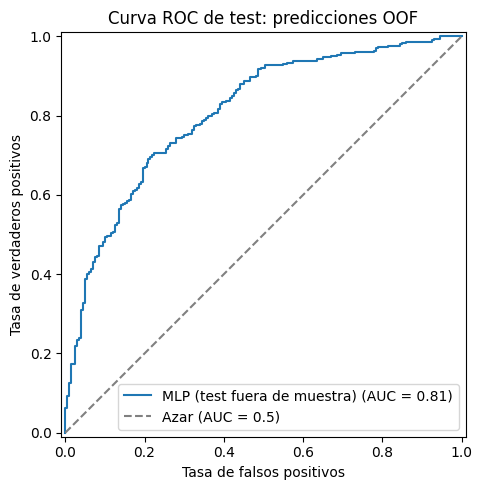

In [5]:
auc_promedio = resultados['auc_test'].mean()
auc_std = resultados['auc_test'].std(ddof=1)
auc_oof = roc_auc_score(y, probabilidades_oof)

print(f'AUC de test promedio (5 folds): {auc_promedio:.4f}')
print(f'Desviación estándar entre folds: {auc_std:.4f}')
print(f'AUC OOF global: {auc_oof:.4f}')

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y, probabilidades_oof, name='MLP (test fuera de muestra)', ax=ax,
)
ax.plot([0, 1], [0, 1], '--', color='gray', label='Azar (AUC = 0.5)')
ax.set(title='Curva ROC de test: predicciones OOF',
       xlabel='Tasa de falsos positivos', ylabel='Tasa de verdaderos positivos')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

Cada fila reporta una arquitectura elegida sin consultar su test. Es normal que los cinco folds elijan arquitecturas diferentes. No se elige un ganador por AUC de test: eso usaría el test para seleccionar el modelo.

Referencia: [validación cruzada anidada de scikit-learn](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html).